# Krok 8. Typy popytu SKU (E4)
**Wynik z instrukcji:** każde SKU dostaje jeden z 4 typów popytu (np. kajzerka = regularny, bombonierka = nieregularny), a dla każdego typu ustalamy, jak liczyć jego prognozę (np. regularny: zwykła średnia; sporadyczny: średnia z dłuższego okresu, bo mediana dałaby 0). Poziom: SKU. Dla wszystkich wariantów.

**Klasyfikacja (Syntetos-Boylan).** Dwie liczby opisują popyt towaru: **ADI** (średni odstęp w tygodniach między tygodniami ze sprzedażą) i **CV²** (jak różne są wielkości sprzedaży w tygodniach ze sprzedażą). Progi z literatury, zgodne ze specyfikacją: ADI 1,32 i CV² 0,49.

| | CV² < 0,49 | CV² ≥ 0,49 |
|---|---|---|
| **ADI < 1,32** | regularny | zmienny |
| **ADI ≥ 1,32** | sporadyczny | nieregularny |

Towary z mniej niż 13 tygodniami od pierwszej sprzedaży dostają `za_malo_danych` (zimny start, krok 9). Okres jest tygodniowy, bo na tym poziomie liczą się warianty. Przy innym okresie (dziennym) niemal wszystkie towary wyglądałyby na sporadyczne, więc progi trzeba by przeliczyć.

**Reguła prognozy dla typu.** Sprawdzamy pięć reguł w teście 2023 → 2024 (typ wyznaczony z 2023, żeby nie podpatrywać 2024) i wybieramy tę o najmniejszym WAPE spośród reguł, które zachowują sumę sprzedaży (obciążenie w granicach ±30 %).

**Wynik zapisany do:** `dane/eda/wynik_08_typy_popytu.csv` (typ każdego SKU) i `dane/eda/wynik_08_reguly.csv` (reguła na typ).

In [5]:
# Ustawienia wspólne: moduł eda_wspolne.py leży obok tego notebooka
import os, sys
sys.path.insert(0, os.getcwd())
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_wspolne as ew

ew.wejdz_do_korzenia()      # przechodzi do katalogu głównego projektu (tam, gdzie jest plik z danymi)
ew.styl()
print("Katalog projektu:", os.getcwd(), "| EDA używa danych do", ew.KONIEC_EDA.date(), "(rok testowy", ew.ROK_TEST, "pomijamy)")

Katalog projektu: /Users/mixer/python/analiza_sprzedazy_w_sklepie | EDA używa danych do 2024-12-31 (rok testowy 2025 pomijamy)


## Klasyfikacja wszystkich towarów
#### Objaśnienie
**Po co.** Nadajemy każdemu towarowi typ na podstawie obu lat EDA (ten wynik zapisujemy dla kolejnych kroków).
**Co robi kod.** Buduje tabelę sprzedaży tygodniowej (towary × 104 tygodnie) i wywołuje `typ_popytu` z modułu. Liczy od tygodnia **pierwszej sprzedaży** (wcześniejsze zera oznaczają brak w ofercie). Pokazuje liczbę towarów, udział w sprzedaży i medianę ADI oraz CV² dla każdego typu, a na wykresie każdy towar jako punkt w układzie ADI-CV² z liniami progów.
**Jak czytać wynik.** Towarów rzadkich jest zwykle dużo, a ich udział w sprzedaży mały: typ „regularny” to często kilka procent towarów, które dają większość wolumenu. To uzasadnia różne metody dla różnych typów.
**Udział zer** to część tygodni (od pierwszej sprzedaży) bez sprzedaży: dla sporadycznych przekracza połowę, a wtedy mediana wynosi 0.

                towary  ADI_mediana  CV2_mediana  udzial_zer  udzial_towarow_%  udzial_sprzedazy_%
typ                                                                                               
nieregularny      1160         3.09         0.68        0.68             11.67                5.88
regularny         2535         1.06         0.30        0.05             25.50               72.16
sporadyczny       5361         4.33         0.22        0.77             53.92               13.75
za_malo_danych     482         1.67         0.12        0.40              4.85                0.27
zmienny            404         1.14         0.61        0.12              4.06                7.94


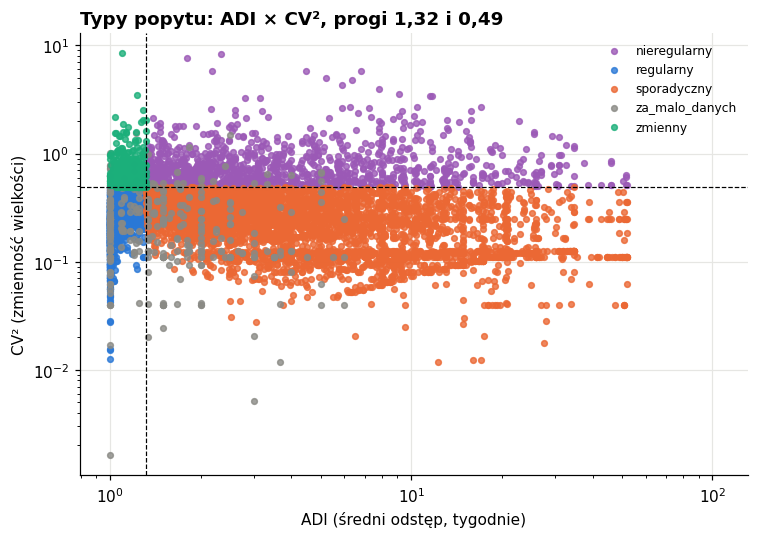

In [6]:
fa = ew.wczytaj_sprzedaz()
kal = ew.kalendarz()
tyg = ew.panel_tygodniowy(fa, kal, "SKU")
del fa
assert tyg.shape[1] == 104, f"oczekiwano 104 tygodni, jest {tyg.shape[1]} ({tyg.columns[0].date()} … {tyg.columns[-1].date()})"
typ = ew.typ_popytu(tyg)
tab = typ.groupby("typ").agg(towary=("sprzedaz", "size"), sprzedaz=("sprzedaz", "sum"), ADI_mediana=("ADI", "median"),
                             CV2_mediana=("CV2", "median"), udzial_zer=("udzial_zer", "median"))
tab["udzial_towarow_%"] = 100 * tab["towary"] / tab["towary"].sum()
tab["udzial_sprzedazy_%"] = 100 * tab["sprzedaz"] / tab["sprzedaz"].sum()
print(tab.drop(columns="sprzedaz").round(2).to_string())

kol_typ = {"regularny": ew.NIEB, "zmienny": ew.MOR, "sporadyczny": ew.POM, "nieregularny": "#9b59b6", "za_malo_danych": ew.SZARY}
fig, ax = plt.subplots(figsize=(7, 5))
for t, d in typ.groupby("typ"):
    ax.scatter(d["ADI"], d["CV2"], s=14, color=kol_typ[t], label=t, alpha=0.8)
ax.axvline(ew.ADI_PROG, color="black", lw=0.8, ls="--"); ax.axhline(ew.CV2_PROG, color="black", lw=0.8, ls="--")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("ADI (średni odstęp, tygodnie)"); ax.set_ylabel("CV² (zmienność wielkości)")
ax.set_title("Typy popytu: ADI × CV², progi 1,32 i 0,49"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## Jak prognozować każdy typ: test pięciu reguł
#### Objaśnienie
**Po co.** Dla każdego typu wybieramy regułę liczenia prognozy stałej (jedna liczba na tydzień). Uczymy na 2023, sprawdzamy na 2024; typ pochodzi tylko z 2023.
**Reguły.**
- `srednia_wszystkie`: średnia ze wszystkich tygodni aktywnych (dłuższy okres).
- `srednia_13`: średnia z ostatnich 13 tygodni (krótszy okres, szybsza reakcja).
- `mediana`: mediana tygodni aktywnych.
- `croston_sba`: metoda Crostona z korektą Syntetosa-Boylana, zaprojektowana dla popytu przerywanego. Osobno wygładza wielkość sprzedaży (`z`) i odstęp między sprzedażami (`p`), prognoza to `(1 − α/2) · z / p`, α = 0,1.
- `zero`: prognoza zawsze 0 (poprzeczka pokazująca, co robi WAPE przy rzadkim popycie).
**Wybór.** Najmniejszy WAPE spośród reguł z obciążeniem w granicach ±30 % (`BIAS_MAX`). Bez tego warunku wygrywałaby prognoza zaniżona, bo WAPE nagradza niskie prognozy przy popycie z wieloma zerami, a taka prognoza nie służy do zamówień. Prognoza zawyżona o więcej niż 30 % też jest odrzucona: zamawiałaby za dużo.
**Jak czytać wynik.** Dla regularnych różnice między regułami są małe, a krótka średnia lub średnia długa wygrywa o niewiele. Dla sporadycznych i nieregularnych widać wyraźnie, że mediana i zero mają silnie ujemne obciążenie, a Croston lub średnia z długiego okresu zachowują sumę.

In [7]:
def croston_sba(y, alpha=0.1):
    # inicjalizacja z pierwszych 4 sprzedaży, potem wygładzanie przy każdej kolejnej sprzedaży
    nz = np.flatnonzero(y > 0)
    if len(nz) == 0:
        return 0.0
    if len(nz) <= 4:                                  # za mało sprzedaży na wygładzanie: średni odstęp z całej serii
        return (1 - alpha / 2) * y[nz].mean() / (len(y) / len(nz))
    k = 4
    z, p, ostatnia = y[nz[:k]].mean(), (nz[k - 1] + 1) / k, nz[k - 1]
    for i in nz[k:]:
        z = alpha * y[i] + (1 - alpha) * z
        p = alpha * (i - ostatnia) + (1 - alpha) * p
        ostatnia = i
    return (1 - alpha / 2) * z / p

T = 52
A = tyg.values.astype(float)
akt = ew.aktywne_tygodnie(tyg)
typ_ucz = ew.typ_popytu(tyg.iloc[:, :T])
n_akt = akt[:, :T].sum(axis=1)
ok = (n_akt >= 26) & (typ_ucz["typ"].values != "za_malo_danych")
idx = np.flatnonzero(ok)
import warnings
prog = {r: np.zeros(len(idx)) for r in ["srednia_wszystkie", "srednia_13", "mediana", "croston_sba", "zero"]}
for n, i in enumerate(idx):
    y = A[i, :T][akt[i, :T]]                                    # tygodnie od pierwszej sprzedaży
    prog["srednia_wszystkie"][n] = y.mean()
    prog["srednia_13"][n] = y[-13:].mean()
    prog["mediana"][n] = np.median(y)
    prog["croston_sba"][n] = croston_sba(y)
test = A[idx][:, T:]
ty = typ_ucz["typ"].values[idx]
wiersze = []
for t in ["regularny", "zmienny", "sporadyczny", "nieregularny"]:
    m = ty == t
    if not m.any():
        continue
    a = test[m]
    for r, f in prog.items():
        ff = f[m][:, None] * np.ones_like(a)
        wiersze.append({"typ": t, "regula": r, "towary": int(m.sum()), "WAPE_%": 100 * np.abs(a - ff).sum() / a.sum(),
                        "obciazenie_%": 100 * (ff.sum() / a.sum() - 1)})
tw = pd.DataFrame(wiersze)
print(tw.pivot(index="regula", columns="typ", values="WAPE_%").round(1).to_string())
print("\nObciążenie (%):")
print(tw.pivot(index="regula", columns="typ", values="obciazenie_%").round(1).to_string())

typ                nieregularny  regularny  sporadyczny  zmienny
regula                                                          
croston_sba               251.6       48.1        210.6     76.2
mediana                   109.4       48.2        112.5     74.0
srednia_13                145.2       49.0        112.2     76.6
srednia_wszystkie         183.7       49.3        156.8     80.7
zero                      100.0      100.0        100.0    100.0

Obciążenie (%):
typ                nieregularny  regularny  sporadyczny  zmienny
regula                                                          
croston_sba               151.1        1.2        113.8      7.1
mediana                   -38.4        1.8        -10.1    -17.1
srednia_13                 32.9        6.2          1.6      6.3
srednia_wszystkie          78.6        7.9         56.6     12.2
zero                     -100.0     -100.0       -100.0   -100.0


## Wybór reguły i zapis
#### Objaśnienie
**Po co.** Zamieniamy wyniki testu w jedną regułę na typ i zapisujemy ją razem z typami towarów.
**Co robi kod.** `BIAS_MAX` = 30 %: odrzuca reguły, które zaniżają lub zawyżają sumę sprzedaży o więcej niż 30 %. Z pozostałych wybiera najmniejszy WAPE (gdy żadna nie mieści się w granicach, bierze najmniej obciążoną). Typy `za_malo_danych` (zimny start) dostają regułę zastępczą „średnia z dostępnych tygodni, a przy braku sprzedaży 0” i są omówione w kroku 9.
**Uwaga o ostrożności.** To jedno przejście 2023 → 2024. Różnice poniżej kilku punktów procentowych między regułami traktuj jak remis i wybieraj prostszą (średnia).

In [8]:
BIAS_MAX = 30
wybrane = []
for t, d in tw.groupby("typ"):
    dop = d[d["obciazenie_%"].abs() <= BIAS_MAX]
    wybrane.append(dop.loc[dop["WAPE_%"].idxmin()] if len(dop) else d.loc[d["obciazenie_%"].abs().idxmin()])   # brak reguły w granicach: najmniej obciążona
najlepsze = pd.DataFrame(wybrane).set_index("typ")
najlepsze = najlepsze[["regula", "WAPE_%", "obciazenie_%", "towary"]]
najlepsze.loc["za_malo_danych"] = ["srednia_z_dostepnych_tygodni", np.nan, np.nan, int((typ["typ"] == "za_malo_danych").sum())]
print(najlepsze.round(1).to_string())
ew.zapisz_wynik(typ, "wynik_08_typy_popytu.csv")
ew.zapisz_wynik(najlepsze, "wynik_08_reguly.csv")

                                      regula  WAPE_%  obciazenie_%  towary
typ                                                                       
nieregularny                      srednia_13   145.2          32.9     604
regularny                        croston_sba    48.1           1.2    2464
sporadyczny                       srednia_13   112.2           1.6    3238
zmienny                              mediana    74.0         -17.1     321
za_malo_danych  srednia_z_dostepnych_tygodni     NaN           NaN     482
Zapisano: dane/eda/wynik_08_typy_popytu.csv (9942 wierszy)
Zapisano: dane/eda/wynik_08_reguly.csv (5 wierszy)


'dane/eda/wynik_08_reguly.csv'